![Banner](../images/09_13_banner_rs_capstones.png)


# Mapping the 2026 Big Sur Wildfire with Time-Series Sentinel-1 SAR and Sentinel-2 Optical Images

In August 2026 a wildfire burned through the Santa Lucia Range on the Big Sur coast of California, inside the area of interest of this notebook.


## Overview

The terrain is steep (half of the land is steeper than 30°), the vegetation is a mix of chaparral, coastal scrub, grassland and redwood and oak forest, and the coast is often under the marine layer (fog). During the fire, smoke covered much of the area.

The two Sentinel missions see this event in different ways:

- **Sentinel-2** (optical, 10–20 m, every 2–3 days with both satellites) measures what fire does to leaves: the near infrared drops and the shortwave infrared rises. The **Normalized Burn Ratio** (NBR) and its difference (dNBR) are the standard measure of **burn severity**. Clouds and fog block the view; thin smoke blocks the visible bands but much less the shortwave infrared.
- **Sentinel-1** (C-band SAR, 10 m, here every 6 days on two orbits) sees through clouds, fog and smoke. It responds to the *structure* and *moisture* of the vegetation and soil, so a fire changes the backscatter, but less directly than it changes NBR.

In this notebook we:

1. read the AOI (`AOI_Big_Sur.geojson`) and **search the Microsoft Planetary Computer** for Sentinel-1 RTC (two orbits) and Sentinel-2 L2A from 15 July to 31 October 2026;
2. download and cache the full time series at 10 m, plus the Copernicus 30 m DEM;
3. mask clouds per pixel, find the **cloud-free dates**, and detect **smoke** that the cloud mask misses;
4. map **burn severity** (dNBR, RdNBR, Key & Benson classes), separate fire from drying grassland, and compare the burn indices of GeoLattice;
5. date when every pixel burned and reconstruct the **fire growth** from Sentinel-2;
6. normalise and filter the Sentinel-1 series, model the **terrain geometry** of both orbits, and measure the **SAR burn signature**;
7. map the burned area **from SAR alone** with the omnibus change test, a threshold, and a Random Forest trained on the optical map with spatial block validation, and **date the burn from SAR**;
8. relate severity and SAR detection to slope and aspect, and write perimeters, rasters and tables.

**Study period:** 15 July – 31 October 2026, as requested. The last clear Sentinel-2 image without a burn is from 6 August; the fire was burning on 11 August and had reached its final extent by 31 August.


## Core concepts

### Learning objectives

After working through this notebook you will be able to:

- build a Sentinel-1 and Sentinel-2 time series for one AOI from a STAC catalogue, and choose cloud-free optical dates with the scene classification layer;
- explain why smoke hides the visible bands but not the shortwave infrared, and detect smoke-affected dates;
- compute NBR, dNBR and RdNBR with `geolattice.rsense.optical.sensors.sentinel2_burn_indices`, classify burn severity, and separate a fire from seasonal drying;
- reconstruct the daily growth of a fire from the date each pixel burned;
- explain how fire changes C-band backscatter, why the effect depends on slope and look direction, and why averaging matters;
- use `geolattice.rsense.sar.change` (omnibus test, thresholding) and a Random Forest with spatial block validation to map a burn from SAR alone;
- judge what each sensor can and cannot tell you about a fire.

### Contents

1. [Setup](#Setup)
2. [Why both sensors: burn indices, smoke and the SAR response to fire](#Why-both-sensors:-burn-indices,-smoke-and-the-SAR-response-to-fire)
3. [Area of interest](#Area-of-interest)
4. [Searching the Planetary Computer: inventory of the scenes](#Searching-the-Planetary-Computer:-inventory-of-the-scenes)
5. [Downloading and caching the time series](#Downloading-and-caching-the-time-series)
6. [The Sentinel-2 time series: clouds, cloud-free dates and smoke](#The-Sentinel-2-time-series:-clouds,-cloud-free-dates-and-smoke)
7. [Burn severity from Sentinel-2](#Burn-severity-from-Sentinel-2)
8. [Fire growth from Sentinel-2](#Fire-growth-from-Sentinel-2)
9. [The Sentinel-1 time series: quality control, normalisation and speckle filtering](#The-Sentinel-1-time-series:-quality-control,-normalisation-and-speckle-filtering)
10. [Terrain and SAR viewing geometry](#Terrain-and-SAR-viewing-geometry)
11. [The SAR burn signature](#The-SAR-burn-signature)
12. [Mapping the burn from Sentinel-1 alone](#Mapping-the-burn-from-Sentinel-1-alone)
13. [Fire growth from Sentinel-1](#Fire-growth-from-Sentinel-1)
14. [Terrain effects on severity and on SAR detection](#Terrain-effects-on-severity-and-on-SAR-detection)
15. [Writing the outputs](#Writing-the-outputs)
16. [Interpretation, caveats and recommended recipe](#Interpretation,-caveats-and-recommended-recipe)


## Task and evaluation design

- **Data:** Sentinel-2 L2A (all scenes with less than 90 % cloud, per-pixel cloud masking), Sentinel-1 IW GRD radiometric terrain-corrected γ⁰ (Planetary Computer `sentinel-1-rtc`) on ascending orbit 35 and descending orbit 42, and the Copernicus GLO-30 DEM.
- **Reference.** No official perimeter or field severity plots are used. The **Sentinel-2 dNBR perimeter** serves as the reference for the SAR maps; it is itself a remote-sensing product, so the SAR scores measure agreement with optics, not accuracy against the ground.
- **Spatial validation.** The SAR Random Forest is evaluated on 1 km spatial blocks that were not used in training (`ic.spatial_block_split`, `ic.check_split_isolation`).


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import time, json, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from rasterio import features as rfeat
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from shapely.geometry import box, shape
from shapely.ops import unary_union
from scipy import ndimage as ndi

import pystac_client, planetary_computer as pc, odc.stac
from odc.geo.geobox import GeoBox

import geolattice
import geolattice.rsense.classify.image_classification as ic
import geolattice.rsense.optical.sensors.sentinel2_burn_indices as bi
from sklearn.metrics import roc_auc_score
from geolattice.rsense.sar import sentinel1 as s1, speckle, change, sar_indices as sind

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("GeoLattice", geolattice.__version__)

# the notebook runs from its own folder or from the repository root
HERE = Path.cwd()
CANDIDATES = [HERE / "../../../../Data/08_remote_sensing/08_11_Capstones" / "s1_Big _Sur_wildfires",
              HERE / "Data/08_remote_sensing/08_11_Capstones/s1_Big _Sur_wildfires"]
DATA = next(p for p in CANDIDATES if p.exists())
OUT = DATA.parent.parent / "outputs" / "big_sur_wildfire"
CACHE = DATA / "cache"
for p in (OUT, CACHE):
    p.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:32610"                      # UTM 10N, the zone of the Big Sur coast
STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
START, END = "2026-07-15", "2026-10-31"
RES = 10
SEED = 42
rng = np.random.default_rng(SEED)
print("DATA:", DATA)
print("OUT :", OUT)

GeoLattice 0.3.35
DATA: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/data/s1_Big _Sur_wildfires
OUT : /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/outputs/big_sur_wildfire


## Why both sensors: burn indices, smoke and the SAR response to fire

### What fire does to the optical spectrum

Healthy leaves reflect strongly in the near infrared (NIR, Sentinel-2 B8, 842 nm) and absorb in the shortwave infrared (SWIR-2, B12, 2190 nm) because they hold water. Fire removes the leaves and exposes charred, dry ground: NIR drops and SWIR rises. The **Normalized Burn Ratio** combines the two,

$$
\mathrm{NBR}=\frac{\rho_{NIR}-\rho_{SWIR2}}{\rho_{NIR}+\rho_{SWIR2}},\qquad
\mathrm{dNBR}=\mathrm{NBR}_{pre}-\mathrm{NBR}_{post},
$$

and the **relativised** dNBR (Miller & Thode, 2007) removes the dependence on how green the site was before the fire,

$$
\mathrm{RdNBR}=\frac{1000\cdot\mathrm{dNBR}}{\sqrt{\left|\mathrm{NBR}_{pre}\right|}} .
$$

USGS burn severity classes (Key & Benson, 2006) on dNBR:

| dNBR | < −0.10 | −0.10 – 0.10 | 0.10 – 0.27 | 0.27 – 0.44 | 0.44 – 0.66 | ≥ 0.66 |
|---|---|---|---|---|---|---|
| Class | enhanced regrowth | unburned | low | moderate-low | moderate-high | high |

GeoLattice also provides **NBR2** (SWIR-1 vs SWIR-2), the **Burn Area Index** BAI, **BAIS2** (red-edge based) and **MIRBI** (mid-infrared burn index); Section 7 compares them.

### Smoke

Smoke particles are small compared with SWIR wavelengths, so they scatter blue light strongly (Rayleigh-like) and SWIR hardly at all. A smoky scene looks white-blue in true colour but nearly normal in a SWIR composite, and NBR, which uses NIR and SWIR, is only mildly affected. Thin smoke is usually **not** flagged as cloud by the Sentinel-2 scene classification layer (SCL), so we detect it from the blue band.

### What fire does to C-band backscatter

| Before the fire | After the fire | Effect on C-band (λ ≈ 5.6 cm) |
|---|---|---|
| canopy of leaves and twigs: **volume scattering** | canopy gone, stems and bare soil | VH (cross-pol, volume) decreases |
| soil shaded and covered by litter | rough bare soil, ash, rocks exposed: **surface scattering** | VV (co-pol, surface) often increases |
| | | the **cross ratio** VH/VV decreases |

In shrubland the canopy is thin, so the VH loss is small and is offset by the rougher soil. The surface-scattering increase in VV and the drop of the cross ratio are the more reliable signals. Rain changes soil moisture and raises VV everywhere, so post-fire images after the first rain must be interpreted with care.

### Terrain geometry

Sentinel-1 looks sideways at about 30–46° from the vertical. The **local incidence angle** $\theta_{loc}$ between the radar beam and the slope normal is

$$
\cos\theta_{loc}=\cos\theta\cos s+\sin\theta\sin s\cos(\phi_a-\phi_{sensor}),
$$

with incidence angle $\theta$, slope $s$, slope aspect $\phi_a$ and the azimuth $\phi_{sensor}$ from the ground towards the satellite. Slopes facing the sensor are **foreshortened** (small $\theta_{loc}$, many ground metres in one pixel); slopes facing away approach **shadow** ($\theta_{loc}\to 90°$). The ascending orbit looks east, the descending orbit looks west, so the two orbits see opposite slopes well. RTC correction removes most of the brightness effect of slope, but not the loss of resolution.

### Change detection used here

- **Difference in dB** (log ratio): $\Delta = 10\log_{10}(\bar I_{post}/\bar I_{pre})$ of period means.
- **Omnibus likelihood-ratio test** (Conradsen et al., 2016; `change.omnibus_test`): for $k$ images of a pixel with ENL $m$,
$$
\ln Q = m\Big(k\ln k+\sum_i\ln X_i-k\ln\sum_i X_i\Big),\qquad -2\rho\ln Q\ \sim\ \chi^2_{k-1}\ \text{under no change}.
$$
- **Change point:** for a series $x_1..x_n$, the date $k$ minimising $\sum_{i<k}(x_i-\bar x_{<k})^2+\sum_{i\ge k}(x_i-\bar x_{\ge k})^2$.
- **Random Forest:** an ensemble of decision trees on many change features at several spatial scales, $\hat y=\mathrm{mode}\{h_b(\mathbf x)\}$.


## Area of interest


The AOI is a rectangle on the Big Sur coast (NW 36.3237 °N, −121.8028 °E; SE 36.1842 °N, −121.6110 °E). All data are put on one **10 m grid in UTM zone 10N** (EPSG:32610). The Pacific Ocean in the south-west corner is masked with the DEM.


In [2]:
aoi_gdf = gpd.read_file(DATA / "AOI_Big_Sur.geojson").to_crs(4326)
aoi = aoi_gdf.geometry.iloc[0]
aoi_utm = aoi_gdf.to_crs(CRS)
BOUNDS = tuple(np.round(np.array(aoi_utm.total_bounds) / RES) * RES)
gb = GeoBox.from_bbox(BOUNDS, CRS, resolution=RES)
EXT = [BOUNDS[0], BOUNDS[2], BOUNDS[1], BOUNDS[3]]
print("AOI (lon/lat):", np.round(aoi.bounds, 4))
print(f"AOI: {aoi_utm.area.iloc[0] / 1e6:.1f} km²; grid {gb.shape.x} x {gb.shape.y} pixels of {RES} m (UTM 10N)")

AOI (lon/lat): [-121.8028   36.1842 -121.611    36.3237]
AOI: 266.7 km²; grid 1744 x 1571 pixels of 10 m (UTM 10N)


## Searching the Planetary Computer: inventory of the scenes


In [3]:
def search(collection, **kw):
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
    return list(client.search(collections=[collection], intersects=aoi, datetime=f"{START}/{END}", **kw).items())

s1_items = search("sentinel-1-rtc")
S1_BY = {}                                  # (orbit, date) -> items
for it in s1_items:
    key = (it.properties["sat:relative_orbit"], it.datetime.date().isoformat())
    S1_BY.setdefault(key, []).append(it)
s1_inv = pd.DataFrame([{"orbit": o, "date": pd.Timestamp(d), "pass": its[0].properties["sat:orbit_state"],
                        "platform": its[0].properties["platform"].upper().replace("SENTINEL-", "S"),
                        "time (UTC)": its[0].datetime.strftime("%H:%M"),
                        "aoi_coverage": round(unary_union([shape(i.geometry) for i in its]).intersection(aoi).area / aoi.area, 3)}
                       for (o, d), its in sorted(S1_BY.items())])
ORBITS = {o: g.iloc[0]["pass"] for o, g in s1_inv.groupby("orbit")}
print(f"{len(s1_inv)} Sentinel-1 acquisitions:", {f"orbit {o} ({p})": int((s1_inv.orbit == o).sum()) for o, p in ORBITS.items()})
print("platforms:", s1_inv.platform.value_counts().to_dict(), "| minimum AOI coverage:", s1_inv.aoi_coverage.min())
for o in ORBITS:
    d = s1_inv[s1_inv.orbit == o].date
    print(f"orbit {o}: {d.min().date()} to {d.max().date()}, revisit gaps (days): {d.diff().dt.days.value_counts().sort_index().to_dict()}")
s1_inv.groupby("orbit").head(3)

36 Sentinel-1 acquisitions: {'orbit 35 (ascending)': 18, 'orbit 42 (descending)': 18}
platforms: {'S1D': 18, 'S1C': 18} | minimum AOI coverage: 1.0
orbit 35: 2026-07-20 to 2026-10-30, revisit gaps (days): {6.0: 17}
orbit 42: 2026-07-20 to 2026-10-30, revisit gaps (days): {6.0: 17}


,orbit,date,pass,platform,time (UTC),aoi_coverage
0,35,2026-07-20,ascending,S1D,02:06,1.0
1,35,2026-07-26,ascending,S1C,02:06,1.0
2,35,2026-08-01,ascending,S1D,02:06,1.0
18,42,2026-07-20,descending,S1D,14:07,1.0
19,42,2026-07-26,descending,S1C,14:07,1.0
20,42,2026-08-01,descending,S1D,14:07,1.0


**Sentinel-1.** Two relative orbits cover the whole AOI: **ascending orbit 35** (02:06 UTC, about 19:06 local time the previous evening) and **descending orbit 42** (14:07 UTC, 07:07 local time). Each is acquired every **6 days**, alternately by **Sentinel-1C** and **Sentinel-1D**, from 20 July to 30 October: 18 dates per orbit, 36 in total. Both orbits fall on the same UTC days, about 12 hours apart.


In [4]:
s2_items = search("sentinel-2-l2a", query={"eo:cloud_cover": {"lt": 90}})
S2_BY = {}
for it in s2_items:
    S2_BY.setdefault(it.datetime.date().isoformat(), []).append(it)
S2_BY = dict(sorted(S2_BY.items()))
s2_inv = pd.DataFrame([{"date": pd.Timestamp(d), "tiles": ", ".join(sorted(i.properties["s2:mgrs_tile"] for i in its)),
                        "scene cloud % (mean)": round(np.mean([i.properties["eo:cloud_cover"] for i in its]), 1)}
                       for d, its in S2_BY.items()]).set_index("date")
print(f"{len(s2_inv)} Sentinel-2 days with scene cloud < 90 % ({len(s2_items)} tiles)")
s2_inv.T

25 Sentinel-2 days with scene cloud < 90 % (47 tiles)


date,2026-07-17,2026-07-22,2026-07-27,2026-08-01,2026-08-03,2026-08-06,2026-08-11,2026-08-16,2026-08-21,2026-08-23,...,2026-09-15,2026-09-20,2026-09-25,2026-09-30,2026-10-05,2026-10-10,2026-10-15,2026-10-20,2026-10-22,2026-10-30
tiles,"10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF",10SFF,"10SEF, 10SFF","10SEF, 10SFF",10SFF,"10SEF, 10SFF","10SEF, 10SFF",...,"10SEF, 10SFF",10SFF,"10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF","10SEF, 10SFF",10SFF,"10SEF, 10SFF"
scene cloud % (mean),40.2,24.0,27.4,43.4,5.3,46.7,44.6,35.8,55.4,61.1,...,44.3,82.8,6.1,34.1,37.2,11.2,0.0,80.7,81.5,70.9


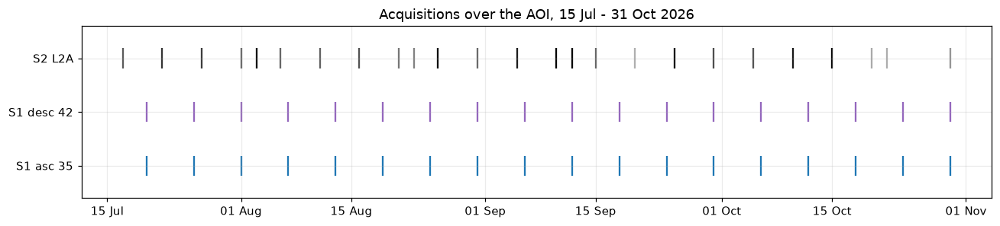

In [5]:
fig, ax = plt.subplots(figsize=(12, 2.8))
for y, (o, c) in enumerate([(35, "tab:blue"), (42, "tab:purple")]):
    d = s1_inv[s1_inv.orbit == o]
    ax.scatter(d.date, np.full(len(d), y), marker="|", s=300, color=c, label=f"S1 orbit {o} ({ORBITS[o]})")
ax.scatter(s2_inv.index, np.full(len(s2_inv), 2), marker="|", s=300,
           c=plt.cm.Greys(0.3 + 0.7 * (1 - s2_inv["scene cloud % (mean)"].values / 100)), label="S2 (darker = less cloud)")
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["S1 asc 35", "S1 desc 42", "S2 L2A"]); ax.set_ylim(-0.6, 2.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.set_title("Acquisitions over the AOI, 15 Jul - 31 Oct 2026")
plt.tight_layout(); plt.show()

**Sentinel-2.** Two tiles (10SEF and 10SFF) cover the AOI. With several Sentinel-2 satellites in orbit, the AOI is imaged every 2–5 days; 25 days have less than 90 % scene cloud. Scene-level cloud cover is a poor guide here, because a tile is much larger than the AOI, so clouds are judged per pixel in Section 6.


## Downloading and caching the time series


For each Sentinel-1 date and orbit we load VV and VH, and for each Sentinel-2 day the ten 10–20 m bands and the SCL, all resampled onto the same 10 m grid (bilinear for reflectance and backscatter, nearest for the SCL), and write one compressed NetCDF per date. L2A digital numbers carry an offset of 1000 since processing baseline 04.00, so reflectance = (DN − 1000) / 10 000. The Copernicus GLO-30 DEM is resampled to the same grid. The download takes about 3 minutes; later runs read the cache (set `RUN_DOWNLOAD = False` to work offline).


In [6]:
RUN_DOWNLOAD = True
S1_CACHE, S2_CACHE = CACHE / "s1_rtc_10m", CACHE / "s2_l2a_10m"
S2_BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]

def save(ds, f, attrs):
    ds = ds.drop_vars([v for v in ds.coords if v not in ("x", "y")]).compute()
    ds.attrs = attrs
    tmp = f.with_suffix(".tmp")
    ds.to_netcdf(tmp, engine="h5netcdf", encoding={v: {"zlib": True, "complevel": 4} for v in ds.data_vars})
    tmp.rename(f)
    return f

def fetch_s1(key):
    o, d = key
    f = S1_CACHE / f"S1_o{o:03d}_{d.replace('-', '')}.nc"
    if f.exists():
        return f
    ds = odc.stac.load(S1_BY[key], bands=["vv", "vh"], geobox=gb, groupby="solar_day", resampling="bilinear",
                       chunks={}).squeeze("time", drop=True)
    return save(ds, f, {"date": d, "orbit": o, "units": "gamma0 linear"})

def fetch_s2(d):
    f = S2_CACHE / f"S2_{d.replace('-', '')}.nc"
    if f.exists():
        return f
    ds = odc.stac.load(S2_BY[d], bands=S2_BANDS + ["SCL"], geobox=gb, groupby="solar_day",
                       resampling={"SCL": "nearest", "*": "bilinear"}, chunks={}).squeeze("time", drop=True)
    return save(ds, f, {"date": d, "units": "DN (reflectance = (DN - 1000) / 10000)"})

def fetch_all(fn, keys, cache, workers=6):
    cache.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    with ThreadPoolExecutor(workers) as ex:
        files = list(ex.map(fn, keys))
    print(f"{cache.name}: {len(files)} files ready in {time.time() - t0:.0f} s")

dem_f = CACHE / "copdem30_10m.nc"
if RUN_DOWNLOAD:
    fetch_all(fetch_s1, list(S1_BY), S1_CACHE)
    fetch_all(fetch_s2, list(S2_BY), S2_CACHE)
    if not dem_f.exists():
        client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
        dem_items = list(client.search(collections=["cop-dem-glo-30"], intersects=aoi).items())
        dem = odc.stac.load(dem_items, bands=["data"], geobox=gb, resampling="bilinear", chunks={}).isel(time=0)["data"]
        save(dem.astype("float32").to_dataset(name="elevation"), dem_f, {"source": "Copernicus DEM GLO-30"})
print("DEM:", dem_f.name)

s1_rtc_10m: 36 files ready in 0 s
s2_l2a_10m: 25 files ready in 0 s
DEM: copdem30_10m.nc


## The Sentinel-2 time series: clouds, cloud-free dates and smoke


A pixel is **clear** when the SCL calls it dark area, vegetation, bare soil, water, unclassified or snow. Clouds, cirrus, cloud shadows, saturated and no-data pixels are masked. The "dark area" class must be kept: freshly charred ground is so dark that the classifier puts it there, and masking it would punch holes in the burn scar.


In [7]:
dem = xr.open_dataset(dem_f).elevation.values
land = dem > 1.0                                   # the Pacific is masked with the DEM (sea level = 0 m)

fs = sorted(S2_CACHE.glob("S2_*.nc"))
s2 = xr.concat([xr.open_dataset(f).load() for f in fs],
               dim=pd.Index(pd.to_datetime([f.stem[3:] for f in fs], format="%Y%m%d"), name="time"))
refl = ((s2[S2_BANDS].astype("float32") - 1000) / 10000).clip(0, 1)
scl = s2.SCL.values
# clear = dark area, vegetation, bare soil, water, unclassified or snow in the scene classification layer; clouds,
# cirrus, cloud shadows, saturated and no-data pixels are masked. "Dark area" (2) must be kept: freshly burned
# ground (char) is so dark that the classifier puts it in this class.
clear = np.isin(scl, [2, 4, 5, 6, 7, 11]) & (s2.B04.values > 0)
refl = refl.where(xr.DataArray(clear, dims=("time", "y", "x"), coords={"time": s2.time}))
s2_times = pd.DatetimeIndex(s2.time.values)
clear_land = pd.Series(clear[:, land].mean(1), index=s2_times)
print(f"{len(s2_times)} Sentinel-2 days loaded; land pixels: {land.mean() * 100:.0f} % of the AOI")
pd.DataFrame({"clear land (%)": (clear_land * 100).round(1)}).T

25 Sentinel-2 days loaded; land pixels: 89 % of the AOI


,2026-07-17,2026-07-22,2026-07-27,2026-08-01,2026-08-03,2026-08-06,2026-08-11,2026-08-16,2026-08-21,2026-08-23,...,2026-09-15,2026-09-20,2026-09-25,2026-09-30,2026-10-05,2026-10-10,2026-10-15,2026-10-20,2026-10-22,2026-10-30
clear land (%),100.0,89.6,99.0,100.0,98.6,98.5,94.8,98.3,90.4,99.5,...,99.1,0.8,100.0,100.0,100.0,100.0,100.0,67.2,0.0,3.7


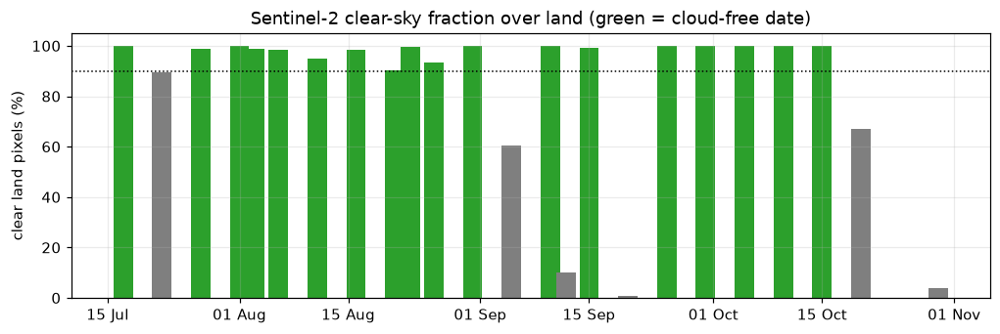

18 cloud-free dates: ['17 Jul', '27 Jul', '01 Aug', '03 Aug', '06 Aug', '11 Aug', '16 Aug', '21 Aug', '23 Aug', '26 Aug', '31 Aug', '10 Sep', '15 Sep', '25 Sep', '30 Sep', '05 Oct', '10 Oct', '15 Oct']


In [8]:
CLEAR_MIN = 0.90                                   # a "cloud-free" date: at least 90 % of the land pixels clear
cloudfree = s2_times[clear_land.values >= CLEAR_MIN]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(s2_times, clear_land * 100, width=2.5, color=np.where(clear_land >= CLEAR_MIN, "tab:green", "tab:grey"))
ax.axhline(CLEAR_MIN * 100, color="k", ls=":", lw=1)
ax.set_ylabel("clear land pixels (%)"); ax.set_title("Sentinel-2 clear-sky fraction over land (green = cloud-free date)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.show()
print(f"{len(cloudfree)} cloud-free dates:", [d.strftime("%d %b") for d in cloudfree])

A date is called **cloud-free** when at least 90 % of the land is clear. 18 of the 25 dates qualify; the gaps are fog over the coast in July and August and the first autumn storms in late October (20, 22 and 30 October).


pre-fire land median blue reflectance: ['0.033', '0.031', '0.031', '0.028', '0.031', '0.037']
mostly clear dates affected by smoke: ['11 Aug', '16 Aug', '21 Aug', '23 Aug', '26 Aug']


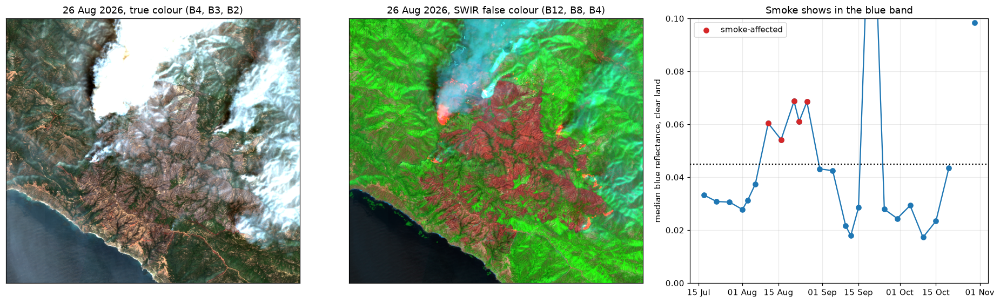

In [9]:
# smoke: the scene classification does not flag thin smoke, but smoke scatters blue light strongly and SWIR hardly at all
raw = ((s2[["B02", "B04", "B03", "B08", "B12"]].astype("float32") - 1000) / 10000).clip(0, 1)
blue_land = pd.Series(np.nanmedian(np.where(clear, raw.B02.values, np.nan)[:, land], 1), index=s2_times)
SMOKE_BLUE = 0.045                                 # land median blue reflectance above which a date is smoke-affected
smoky = s2_times[(blue_land > SMOKE_BLUE).values & (clear_land >= 0.8).values]    # hazy, but not cloud-covered
print("pre-fire land median blue reflectance:", [f"{v:.3f}" for v in blue_land[:"2026-08-06"]])
print("mostly clear dates affected by smoke:", [d.strftime("%d %b") for d in smoky])

d = pd.Timestamp("2026-08-26")
r = raw.sel(time=d)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
ax[0].imshow(np.clip(np.dstack([r.B04, r.B03, r.B02]) / 0.18, 0, 1), extent=EXT); ax[0].set_title("26 Aug 2026, true colour (B4, B3, B2)")
ax[1].imshow(np.clip(np.dstack([r.B12, r.B08, r.B04]) / 0.4, 0, 1), extent=EXT); ax[1].set_title("26 Aug 2026, SWIR false colour (B12, B8, B4)")
ax[2].plot(s2_times, blue_land, "o-", color="tab:blue"); ax[2].axhline(SMOKE_BLUE, color="k", ls=":")
ax[2].scatter(smoky, blue_land[smoky], color="tab:red", zorder=3, label="smoke-affected")
ax[2].set_ylim(0, 0.1); ax[2].set_ylabel("median blue reflectance, clear land"); ax[2].legend()
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax[2].set_title("Smoke shows in the blue band")
for a in ax[:2]:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Smoke.** On 26 August the true-colour image (left) is dominated by smoke plumes and the fire is hard to see; the SWIR composite of the same scene (centre) shows the active fire front (bright orange), the plume source and the dark-red burn scar clearly. Five mostly clear dates (11, 16, 21, 23 and 26 August) have a land-median blue reflectance well above the pre-fire level of about 0.03: they are smoky, although the SCL calls most of their pixels clear. We keep them, because NBR uses only NIR and SWIR, but we do not use them in the pre- or post-fire composites.


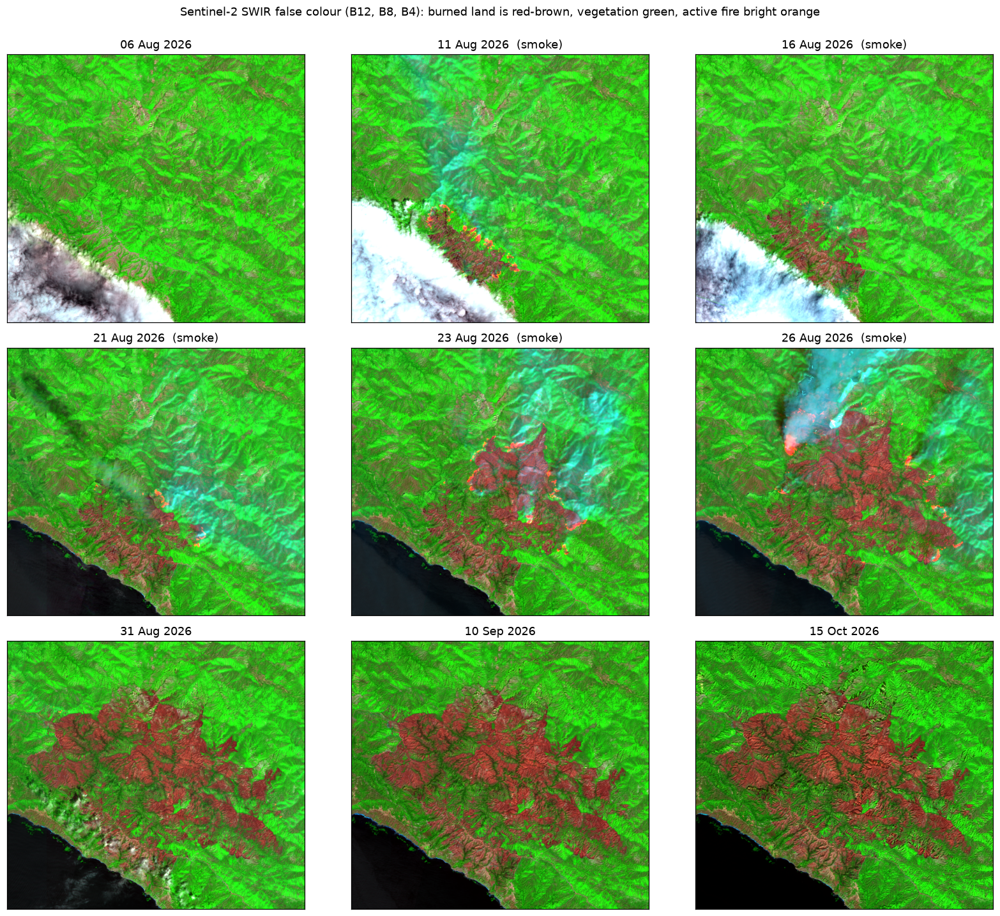

In [10]:
show = [pd.Timestamp(x) for x in ["2026-08-06", "2026-08-11", "2026-08-16", "2026-08-21", "2026-08-23", "2026-08-26",
                                  "2026-08-31", "2026-09-10", "2026-10-15"]]
fig, ax = plt.subplots(3, 3, figsize=(15, 13))
for a, d in zip(ax.ravel(), show):
    r = raw.sel(time=d)
    a.imshow(np.clip(np.dstack([r.B12, r.B08, r.B04]) / 0.4, 0, 1), extent=EXT)
    a.set_title(f"{d:%d %b %Y}" + ("  (smoke)" if d in smoky else "")); a.grid(False); a.set_xticks([]); a.set_yticks([])
fig.suptitle("Sentinel-2 SWIR false colour (B12, B8, B4): burned land is red-brown, vegetation green, active fire bright orange", y=1.0)
plt.tight_layout(); plt.show()

**The fire in pictures.** 6 August is the last clear date without a burn. On 11 August a narrow strip in the south is burning near the coast; the fire then spreads north and north-east (16–26 August), with large runs between 21 and 31 August. From 10 September the scar no longer changes.


## Burn severity from Sentinel-2


**Pre-fire** NBR is the per-pixel median of the clear observations from 15 July to 6 August, and **post-fire** NBR the median from 25 September to 15 October (the fire is out, and the autumn rain has not started). Medians of several dates are robust to the odd missed cloud or fog patch.

**Fire or drying grass?** Between July and October the coastal grassland dries out (it *cures*), which also lowers NBR and gives "low severity" dNBR values along the coast. The difference is speed: a fire drops NBR between two clear observations, curing takes weeks. We therefore require, besides dNBR ≥ 0.10, an NBR drop of at least 0.15 between two consecutive valid observations of the pixel (fog on one date does not hide the drop, because missing dates are skipped). The **fire perimeter** is the largest burned patch plus burned patches of at least 1 ha within 500 m of it, with holes smaller than 1 ha filled.


In [11]:
nbr_t = bi.nbr(refl.B08, refl.B12)                       # NBR of every date, NaN where masked
PRE = ("2026-07-15", "2026-08-06")                       # before the fire: the last clear date without a burn is 6 Aug
POST = ("2026-09-25", "2026-10-15")                      # fire out, before the first autumn rain
nbr_pre = nbr_t.sel(time=slice(*PRE)).median("time")
nbr_post = nbr_t.sel(time=slice(*POST)).median("time")
d_nbr = bi.dnbr(nbr_pre, nbr_post).where(xr.DataArray(land, dims=("y", "x")))
# RdNBR (Miller & Thode 2007): dNBR relative to the pre-fire vegetation, in the usual x1000 units
rdnbr = (1000 * d_nbr) / np.sqrt(np.abs(nbr_pre).clip(0.001))
print(f"pre-fire NBR from {nbr_t.sel(time=slice(*PRE)).sizes['time']} dates, post-fire NBR from "
      f"{nbr_t.sel(time=slice(*POST)).sizes['time']} dates")

SEV = {0: ("Enhanced regrowth", -np.inf, -0.10, "#1a9850"), 1: ("Unburned", -0.10, 0.10, "#d9ef8b"),
       2: ("Low", 0.10, 0.27, "#fee08b"), 3: ("Moderate-low", 0.27, 0.44, "#fdae61"),
       4: ("Moderate-high", 0.44, 0.66, "#f46d43"), 5: ("High", 0.66, np.inf, "#a50026")}
dn = d_nbr.values
sev = np.full(dn.shape, -1, "int8")
for k, (_, lo, hi, _) in SEV.items():
    sev[(dn >= lo) & (dn < hi)] = k
# A fire lowers NBR abruptly, between two clear dates; drying grassland on the coast lowers it slowly over weeks.
# Burned = dNBR >= 0.10 AND a drop of at least 0.15 between two consecutive cloud-free dates.
# drops are taken between consecutive *valid* observations of each pixel, so fog or cloud on one date does not hide them
def ffill_time(a):
    # carry the last valid value forward along axis 0 (time)
    a = a.copy()
    for i in range(1, len(a)):
        a[i] = np.where(np.isnan(a[i]), a[i - 1], a[i])
    return a

nbr_cf = ffill_time(nbr_t.sel(time=cloudfree).values)
max_drop = np.nanmax(nbr_cf[:-1] - nbr_cf[1:], axis=0)
burned_raw = land & (dn >= 0.10) & (max_drop >= 0.15)
# fire perimeter: the largest burned patch plus burned patches of at least 1 ha within 500 m of it; holes < 1 ha filled
bm = ic.clean_mask(burned_raw, min_size=100, hole_size=100, opening=0).astype(bool)
lab, n = ndi.label(bm)
main = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
near = ndi.distance_transform_edt(~main) <= 500 / RES
burned = main | (bm & np.isin(lab, np.unique(lab[near & bm])))
print(f"burn test: drying grass vs fire - median largest single-interval NBR drop {np.nanmedian(max_drop[land & (dn >= 0.1) & (dn < 0.27)]):.2f} "
      f"in the low-severity class, {np.nanmedian(max_drop[land & (dn >= 0.44)]):.2f} in the moderate-high and high classes")
tab = pd.DataFrame({"class": [v[0] for v in SEV.values()],
                    "dNBR range": [f"{v[1]:.2f} to {v[2]:.2f}" for v in SEV.values()],
                    "km² (AOI)": [((sev == k) & land).sum() * RES**2 / 1e6 for k in SEV],
                    "km² inside perimeter": [((sev == k) & burned).sum() * RES**2 / 1e6 for k in SEV]}, index=list(SEV)).round(2)
tab["% of perimeter area"] = (tab["km² inside perimeter"] / tab["km² inside perimeter"].sum() * 100).round(1)
print(f"area inside the fire perimeter: {burned.sum() * RES**2 / 1e6:.1f} km² "
      f"({burned.sum() / land.sum() * 100:.0f} % of the land in the AOI)")
tab

pre-fire NBR from 6 dates, post-fire NBR from 5 dates


burn test: drying grass vs fire - median largest single-interval NBR drop 0.13 in the low-severity class, 0.56 in the moderate-high and high classes
area inside the fire perimeter: 91.4 km² (37 % of the land in the AOI)


,class,dNBR range,km² (AOI),km² inside perimeter,% of perimeter area
0,Enhanced regrowth,-inf to -0.10,2.29,0.00,0.0
1,Unburned,-0.10 to 0.10,133.13,0.50,0.5
2,Low,0.10 to 0.27,26.97,10.43,11.4
3,Moderate-low,0.27 to 0.44,23.00,21.25,23.2
4,Moderate-high,0.44 to 0.66,27.67,27.50,30.1
5,High,0.66 to inf,31.77,31.75,34.7


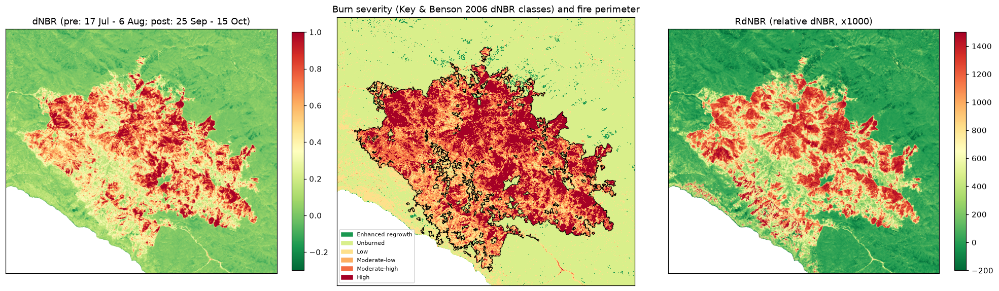

RdNBR classes inside the perimeter (Miller & Thode 2007): unchanged < 69: 0 %, low 69-315: 6 %, moderate 316-640: 23 %, high >= 641: 70 %


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
im = ax[0].imshow(np.where(land, dn, np.nan), cmap="RdYlGn_r", vmin=-0.3, vmax=1.0, extent=EXT)
ax[0].set_title("dNBR (pre: 17 Jul - 6 Aug; post: 25 Sep - 15 Oct)"); plt.colorbar(im, ax=ax[0], fraction=0.04)
cmap = ListedColormap([v[3] for v in SEV.values()]); norm = BoundaryNorm(np.arange(-0.5, 6.5), 6)
ax[1].imshow(np.where(land, sev, np.nan), cmap=cmap, norm=norm, interpolation="nearest", extent=EXT)
ax[1].contour(burned[::-1], levels=[0.5], colors="k", linewidths=0.7, extent=EXT)
ax[1].set_title("Burn severity (Key & Benson 2006 dNBR classes) and fire perimeter")
ax[1].legend(handles=[Patch(color=v[3], label=v[0]) for v in SEV.values()], fontsize=7, loc="lower left")
im = ax[2].imshow(np.where(land, rdnbr.values, np.nan), cmap="RdYlGn_r", vmin=-200, vmax=1500, extent=EXT)
ax[2].set_title("RdNBR (relative dNBR, x1000)"); plt.colorbar(im, ax=ax[2], fraction=0.04)
for a in ax:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
rd = rdnbr.values[burned]
print("RdNBR classes inside the perimeter (Miller & Thode 2007): "
      f"unchanged < 69: {np.mean(rd < 69) * 100:.0f} %, low 69-315: {np.mean((rd >= 69) & (rd < 316)) * 100:.0f} %, "
      f"moderate 316-640: {np.mean((rd >= 316) & (rd < 641)) * 100:.0f} %, high >= 641: {np.mean(rd >= 641) * 100:.0f} %")

**Reading the severity map.** The perimeter encloses about 91 km², 37 % of the land in the AOI. Two thirds of the burned area is moderate-high or high severity, and the RdNBR puts 70 % of the burned area in the "high" class of Miller & Thode (2007): this was a severe fire, typical of chaparral, which burns as a crown fire. The low-severity class *outside* the perimeter, along the coast, is the drying grassland; its median largest single-step NBR drop is about 0.13, against 0.56 in the moderate-high and high classes, so the abrupt-drop test removes it. A few unburned islands remain inside the perimeter.


### Comparing the burn indices of GeoLattice

The same pre- and post-fire median composites give the change of every index. The AUC measures how well each index change separates the perimeter from unburned land more than 100 m outside it.


In [13]:
# the other burn indices in geolattice.rsense.optical.sensors.sentinel2_burn_indices, as post - pre differences of
# the same pre- and post-fire median composites
def composite(sl):
    return refl.sel(time=slice(*sl)).median("time")

pre_c, post_c = composite(PRE), composite(POST)
def all_indices(c):
    return {"NBR": bi.nbr(c.B08, c.B12), "NBR2": bi.nbr2(c.B11, c.B12), "BAI": bi.bai(c.B04, c.B08),
            "BAIS2": bi.bais2(c.B04, c.B06, c.B07, c.B8A, c.B12), "MIRBI": bi.mirbi(c.B12, c.B11)}
IDX_PRE, IDX_POST = all_indices(pre_c), all_indices(post_c)
inside, outside = burned, land & ~burned & (ndi.distance_transform_edt(~burned) * RES > 100)
pick_in = rng.choice(np.flatnonzero(inside.ravel()), 100_000, replace=False)
pick_out = rng.choice(np.flatnonzero(outside.ravel()), 100_000, replace=False)
rows = {}
for k in IDX_PRE:
    d = (IDX_POST[k] - IDX_PRE[k]).values
    yv = np.r_[np.ones(len(pick_in)), np.zeros(len(pick_out))]
    sv = np.nan_to_num(np.r_[d.ravel()[pick_in], d.ravel()[pick_out]])
    a = roc_auc_score(yv, sv)
    rows[k] = {"median change inside": np.nanmedian(d[inside]), "median change outside": np.nanmedian(d[outside]),
               "AUC inside vs outside": max(a, 1 - a), "Spearman r with dNBR (inside)":
               pd.Series(d.ravel()[pick_in]).corr(pd.Series(dn.ravel()[pick_in]), method="spearman")}
print("NBR defines the perimeter, so its AUC is optimistic by construction; the other indices are an independent check.")
pd.DataFrame(rows).T.round(3)

NBR defines the perimeter, so its AUC is optimistic by construction; the other indices are an independent check.


,median change inside,median change outside,AUC inside vs outside,Spearman r with dNBR (inside)
NBR,-0.548,-0.016,0.997,-0.998
NBR2,-0.185,0.005,0.998,-0.908
BAI,146.389,9.890,0.961,0.770
BAIS2,0.584,0.074,0.994,0.793
MIRBI,0.540,0.092,0.964,0.687


All five indices separate burned from unburned land very well. **NBR2** (SWIR-1 vs SWIR-2) and **BAIS2** (red edge and SWIR) are almost as good as NBR and are independent of how the perimeter was drawn; **BAI** and **MIRBI** separate a little less well and follow the severity gradient less closely (lower rank correlation with dNBR). NBR remains the standard for severity because its classes are calibrated against field data (Composite Burn Index).


## Fire growth from Sentinel-2


For each pixel inside the perimeter, the **burn date** is the first clear observation after 6 August at which the pixel has lost at least half of its final NBR drop (and at least 0.10). Using half of the pixel's own final drop, instead of one fixed threshold, makes the date independent of severity. Every Sentinel-2 date counts, including the smoky ones, each with its own cloud mask.


In [14]:
# burn date: the first clear observation at which a perimeter pixel has lost at least half of its final NBR drop
# (and at least 0.10); every Sentinel-2 date is used, with its own per-pixel cloud mask
loss = (nbr_pre - nbr_t).transpose("time", "y", "x").values   # NaN where masked
need = np.maximum(0.10, 0.5 * dn)
after_pre = np.asarray(s2_times > pd.Timestamp(PRE[1]))[:, None, None]   # dates of the pre-fire baseline cannot be burn dates
hit = (loss >= need[None]) & burned[None] & after_pre
valid = ~np.isnan(loss)
first = np.where(hit.any(0), hit.argmax(0), -1)
s2_burn_date = np.where(first >= 0, s2_times.values[np.clip(first, 0, None)], np.datetime64("NaT"))
# the last clear observation before detection: the fire reached the pixel between the two dates
idx = np.arange(len(s2_times))[:, None, None]
prev = np.where(valid & (idx < first[None]), idx, -1).max(0)
gap = np.where((first >= 0) & (prev >= 0), (s2_times.values[np.clip(first, 0, None)] - s2_times.values[np.clip(prev, 0, None)])
               .astype("timedelta64[D]").astype(int), -1)
dated = ~np.isnat(s2_burn_date)
print(f"perimeter pixels with an optical burn date: {dated[burned].mean() * 100:.1f} %; "
      f"median interval between the last unburned and the first burned observation: {np.median(gap[dated & (gap > 0)]):.0f} days")
grow = pd.Series(s2_burn_date[dated]).value_counts().sort_index() * RES**2 / 1e6
growth = pd.DataFrame({"new burned km²": grow.round(2), "cumulative km²": grow.cumsum().round(1)})
growth.index = growth.index.strftime("%d %b")
growth[growth["new burned km²"] > 0].T

perimeter pixels with an optical burn date: 100.0 %; median interval between the last unburned and the first burned observation: 5 days


,11 Aug,16 Aug,21 Aug,23 Aug,26 Aug,31 Aug,05 Sep,10 Sep,15 Sep,25 Sep,30 Sep,05 Oct
new burned km²,10.6,7.14,3.46,23.16,20.2,25.61,0.51,0.31,0.05,0.31,0.03,0.02
cumulative km²,10.6,17.70,21.20,44.40,64.6,90.20,90.70,91.00,91.00,91.40,91.40,91.40


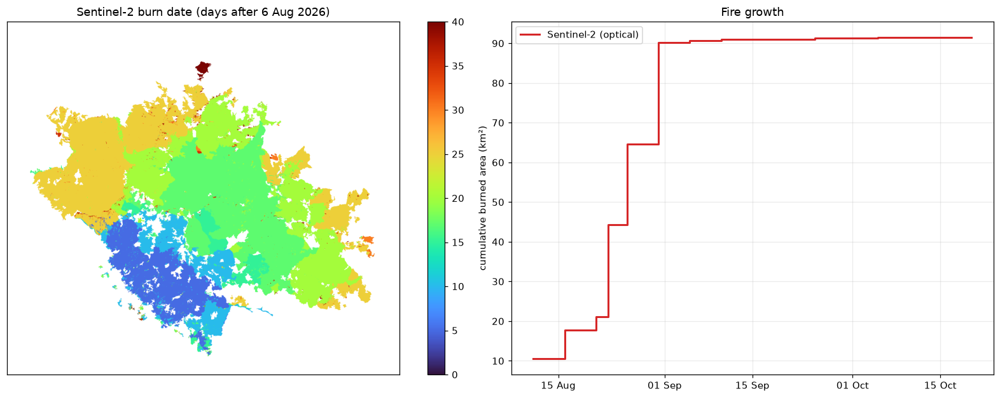

In [15]:
ref = np.datetime64("2026-08-06")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})
days = np.where(dated, (s2_burn_date - ref).astype("timedelta64[D]").astype(float), np.nan)
im = ax[0].imshow(days, cmap="turbo", vmin=0, vmax=40, extent=EXT)
ax[0].set_title("Sentinel-2 burn date (days after 6 Aug 2026)"); plt.colorbar(im, ax=ax[0], fraction=0.04)
ax[0].grid(False); ax[0].set_xticks([]); ax[0].set_yticks([])
cum = pd.Series(s2_burn_date[dated]).value_counts().sort_index().cumsum() * RES**2 / 1e6
ax[1].step(cum.index, cum.values, where="post", color="tab:red", lw=2, label="Sentinel-2 (optical)")
ax[1].set_ylabel("cumulative burned area (km²)"); ax[1].set_title("Fire growth"); ax[1].legend()
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

**Reading the growth.** The fire started near the coast in the south (blue, dated 11 August), burned about 18 km² by 16 August, and then made large runs north and north-east: about 23 km² between 21 and 23 August, 20 km² between 23 and 26 August and 26 km² between 26 and 31 August. By 31 August it had reached about 90 km², and only small additions followed. The median interval between the last unburned and the first burned observation of a pixel is 5 days, which is the time resolution of this reconstruction.


## The Sentinel-1 time series: quality control, normalisation and speckle filtering


As a **stable target** we use unburned land more than 300 m from the perimeter, with no optical change (|dNBR| < 0.05). Its mean backscatter should be constant through the season.


orbit 35 (ascending): 18 dates, 1571 x 1744 px, non-positive or missing: 0
orbit 42 (descending): 18 dates, 1571 x 1744 px, non-positive or missing: 0
stable target: 88.2 km² of unburned land


orbit 35 VH over stable land: mean -13.47 dB, SD 0.39 dB, S1C - S1D +0.28 dB
orbit 35 VV over stable land: mean -7.94 dB, SD 0.23 dB, S1C - S1D +0.15 dB
orbit 42 VH over stable land: mean -13.35 dB, SD 0.40 dB, S1C - S1D +0.42 dB
orbit 42 VV over stable land: mean -7.89 dB, SD 0.29 dB, S1C - S1D +0.31 dB


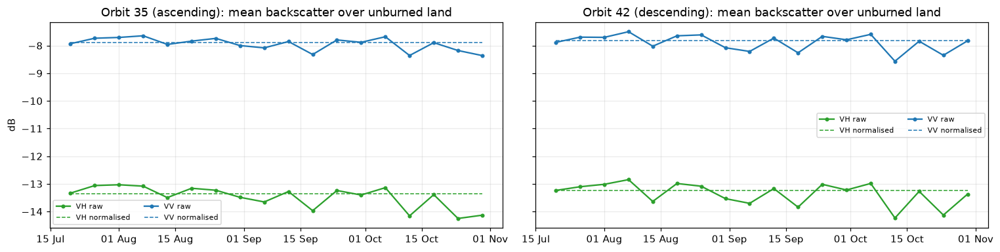

In [16]:
def load_orbit(o):
    fs = sorted(S1_CACHE.glob(f"S1_o{o:03d}_*.nc"))
    t = pd.to_datetime([f.stem.split("_")[-1] for f in fs], format="%Y%m%d")
    return xr.concat([xr.open_dataset(f).load() for f in fs], dim=pd.Index(t, name="time"))

S1 = {o: load_orbit(o) for o in ORBITS}
for o, ds in S1.items():
    bad = int(((ds.vh <= 0) | ds.vh.isnull()).sum())
    print(f"orbit {o} ({ORBITS[o]}): {ds.sizes['time']} dates, {ds.sizes['y']} x {ds.sizes['x']} px, non-positive or missing: {bad:,}")

# stable target: land outside the perimeter that did not change optically (|dNBR| < 0.05), more than 300 m from the fire
far = ndi.distance_transform_edt(~burned) * RES > 300
stable = land & far & (np.abs(dn) < 0.05)
print(f"stable target: {stable.sum() * RES**2 / 1e6:.1f} km² of unburned land")
OFFSET = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for a, (o, ds) in zip(ax, S1.items()):
    for pol, c in [("vh", "tab:green"), ("vv", "tab:blue")]:
        m = 10 * np.log10(ds[pol].values[:, stable].mean(1))
        OFFSET[(o, pol)] = m - np.median(m)                # per-date offset of the stable land from its median
        a.plot(ds.time, m, "o-", ms=3, color=c, label=f"{pol.upper()} raw")
        a.plot(ds.time, m - OFFSET[(o, pol)], "--", lw=1, color=c, label=f"{pol.upper()} normalised")
        print(f"orbit {o} {pol.upper()} over stable land: mean {m.mean():.2f} dB, SD {m.std():.2f} dB, "
              f"S1C - S1D {m[s1_inv[s1_inv.orbit == o].platform.values == 'S1C'].mean() - m[s1_inv[s1_inv.orbit == o].platform.values == 'S1D'].mean():+.2f} dB")
    a.set_title(f"Orbit {o} ({ORBITS[o]}): mean backscatter over unburned land"); a.legend(fontsize=7, ncol=2)
    a.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax[0].set_ylabel("dB")
plt.tight_layout(); plt.show()

# relative radiometric normalisation: remove the per-date offset of the stable land (platform step, rain, wind)
for o, ds in S1.items():
    for pol in ("vh", "vv"):
        ds[pol] = ds[pol] * xr.DataArray(10 ** (-OFFSET[(o, pol)] / 10), dims="time", coords={"time": ds.time})

**Platform offsets.** The stable land varies by only about 0.4 dB (VH) and 0.25 dB (VV), but it zigzags: dates from **Sentinel-1C** are 0.15–0.42 dB brighter than those from **Sentinel-1D**, which alternate on each orbit. On top of that, the first rain in late October darkens VH. We remove both with a **relative radiometric normalisation**: each date is shifted so that its stable-land mean equals the median of the orbit (dashed lines). Fire-related change is then measured relative to the unburned surroundings.

Next, the Quegan & Yu **multi-temporal speckle filter** (`s1.multitemporal_speckle_filter`, 5 × 5 Lee estimator) is applied per orbit and polarisation, and the data are converted to dB.


filtered 2 orbits x 2 polarisations x 18 dates in 10 s


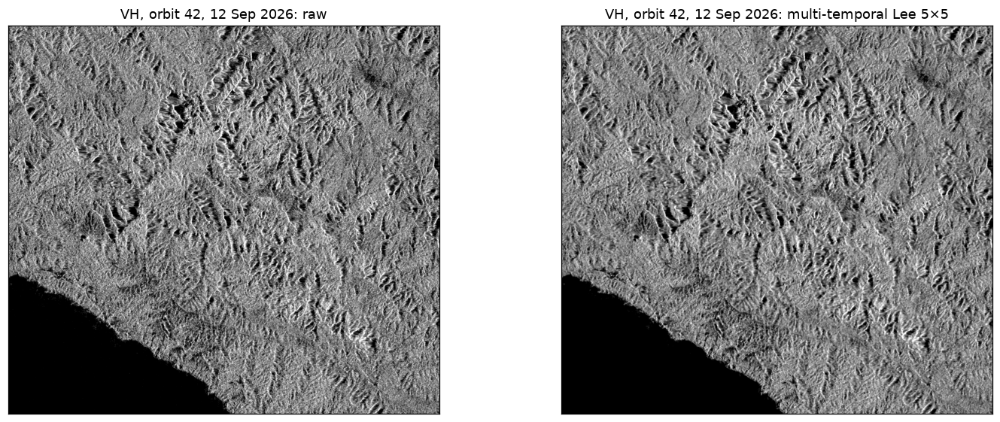

In [17]:
t0 = time.time()
DB = {}
for o, ds in S1.items():
    for pol in ("vh", "vv"):
        DB[(o, pol)] = s1.to_db(s1.multitemporal_speckle_filter(ds[pol], spatial="lee", size=5)).astype("float32")
print(f"filtered 2 orbits x 2 polarisations x 18 dates in {time.time() - t0:.0f} s")

k = 9
raw = 10 * np.log10(S1[42].vh.isel(time=k).values)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, im, t in zip(ax, [raw, DB[(42, "vh")].isel(time=k).values], ["raw", "multi-temporal Lee 5×5"]):
    a.imshow(im, cmap="gray", vmin=-22, vmax=-6, extent=EXT); a.set_title(f"VH, orbit 42, {pd.Timestamp(S1[42].time.values[k]):%d %b %Y}: {t}")
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Terrain and SAR viewing geometry


Slope and aspect come from the DEM. With an incidence angle of about 38° over the AOI and the satellite to the west (ascending, azimuth from the ground to the sensor ≈ 258°) or to the east (descending, ≈ 102°), we compute the local incidence angle of each orbit and call a pixel **usable** when it lies between 15° (strong foreshortening) and 75° (near shadow).


orbit 35 (ascending): local incidence angle median 41°, usable terrain 88 % of land
orbit 42 (descending): local incidence angle median 47°, usable terrain 91 % of land
median slope 29°, slopes > 30°: 46 % of land; unusable in both orbits: 1.8 % of land


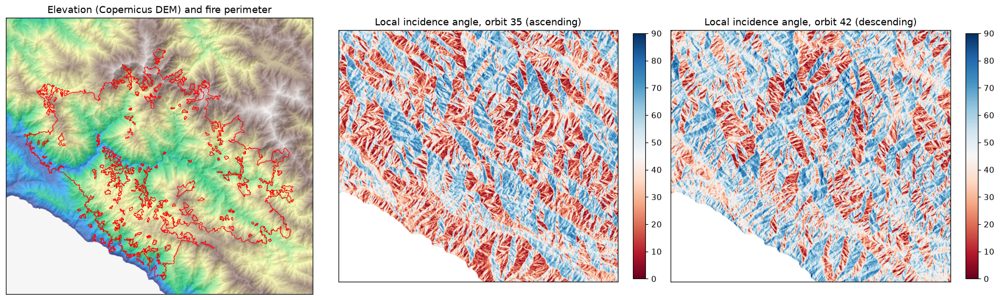

In [18]:
# slope and aspect from the DEM, then the local incidence angle for each orbit
dz_dy, dz_dx = np.gradient(dem, RES)                    # rows run north to south
slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
aspect = (np.degrees(np.arctan2(-dz_dx, dz_dy)) + 360) % 360   # direction the slope faces, clockwise from north
THETA = 38.0                                             # approximate incidence angle over the AOI (IW swath 29-46°)
TO_SENSOR = {35: 258.0, 42: 102.0}                       # azimuth from the ground to the satellite: ascending looks east, descending west
LIA, TERRAIN_OK = {}, {}
for o in ORBITS:
    t, s_, d = np.radians(THETA), np.radians(slope), np.radians(aspect - TO_SENSOR[o])
    LIA[o] = np.degrees(np.arccos(np.clip(np.cos(t) * np.cos(s_) + np.sin(t) * np.sin(s_) * np.cos(d), -1, 1)))
    TERRAIN_OK[o] = land & (LIA[o] > 15) & (LIA[o] < 75)   # no strong foreshortening or grazing/shadow geometry
    print(f"orbit {o} ({ORBITS[o]}): local incidence angle median {np.median(LIA[o][land]):.0f}°, "
          f"usable terrain {TERRAIN_OK[o][land].mean() * 100:.0f} % of land")
both_bad = land & ~TERRAIN_OK[35] & ~TERRAIN_OK[42]
print(f"median slope {np.median(slope[land]):.0f}°, slopes > 30°: {(slope[land] > 30).mean() * 100:.0f} % of land; "
      f"unusable in both orbits: {both_bad[land].mean() * 100:.1f} % of land")

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ls_ = np.clip(np.cos(np.radians(slope)) * 0.7 + 0.3 * np.cos(np.radians(aspect - 315)) * np.sin(np.radians(slope)), 0, 1)
ax[0].imshow(np.where(land, dem, np.nan), cmap="terrain", extent=EXT); ax[0].imshow(ls_, cmap="gray", alpha=0.35, extent=EXT)
ax[0].contour(burned[::-1], levels=[0.5], colors="r", linewidths=0.7, extent=EXT); ax[0].set_title("Elevation (Copernicus DEM) and fire perimeter")
for a, o in zip(ax[1:], ORBITS):
    im = a.imshow(np.where(land, LIA[o], np.nan), cmap="RdBu", vmin=0, vmax=90, extent=EXT)
    a.set_title(f"Local incidence angle, orbit {o} ({ORBITS[o]})"); plt.colorbar(im, ax=a, fraction=0.04)
for a in ax:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The Santa Lucia Range is steep: the median slope is 29° and 46 % of the land is steeper than 30°. Each orbit loses about 10 % of the land to unfavourable geometry, but on **opposite** slopes: the ascending orbit loses west-facing slopes (foreshortened towards the satellite), the descending orbit east-facing ones. Only 1.8 % of the land is unusable in both orbits, which is why two orbits are combined throughout.


## The SAR burn signature


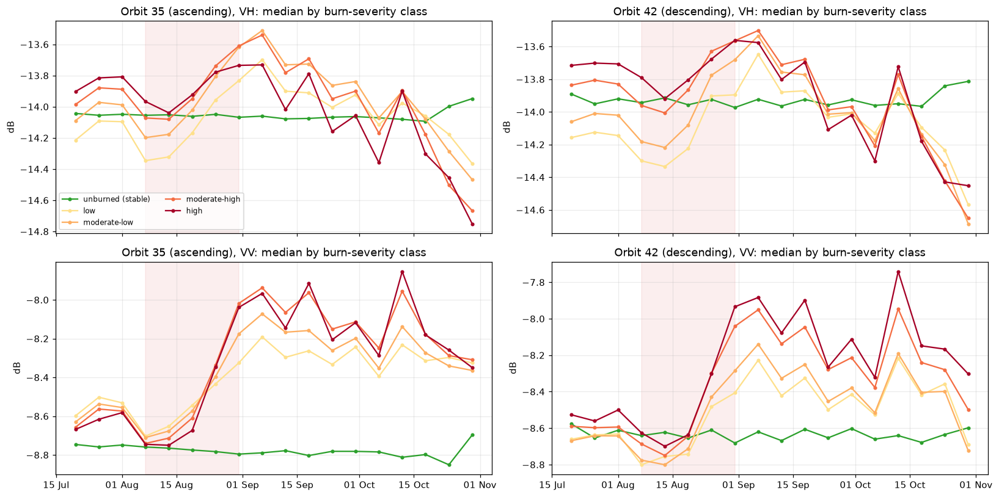

,unburned (stable),low,moderate-low,moderate-high,high
median change post - pre (dB),,,,,
orbit 35 VH,0.01,0.17,0.14,-0.01,-0.22
orbit 35 VV,-0.03,0.31,0.40,0.53,0.58
orbit 42 VH,0.01,0.16,0.12,0.00,-0.18
orbit 42 VV,-0.01,0.31,0.39,0.54,0.58


In [19]:
groups = {"unburned (stable)": stable, "low": burned & (sev == 2), "moderate-low": burned & (sev == 3),
          "moderate-high": burned & (sev == 4), "high": burned & (sev == 5)}
cols = ["tab:green", "#fee08b", "#fdae61", "#f46d43", "#a50026"]
fig, ax = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
for j, o in enumerate(ORBITS):
    for i, pol in enumerate(("vh", "vv")):
        a = ax[i, j]
        db = DB[(o, pol)]
        for (n, m), c in zip(groups.items(), cols):
            mm = m & TERRAIN_OK[o]
            a.plot(db.time, np.median(db.values[:, mm], axis=1), "o-", ms=3, color=c, label=n)
        a.axvspan(pd.Timestamp("2026-08-07"), pd.Timestamp("2026-08-31"), color="tab:red", alpha=0.08)
        a.set_title(f"Orbit {o} ({ORBITS[o]}), {pol.upper()}: median by burn-severity class"); a.set_ylabel("dB")
ax[0, 0].legend(fontsize=8, ncol=2); ax[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

# change from the pre-fire mean to the post-fire mean, per orbit and polarisation
S1_PRE, S1_POST = ("2026-07-15", "2026-08-07"), ("2026-09-06", "2026-10-30")
rows = {}
for o in ORBITS:
    for pol in ("vh", "vv"):
        db = DB[(o, pol)]
        d = (db.sel(time=slice(*S1_POST)).mean("time") - db.sel(time=slice(*S1_PRE)).mean("time")).values
        rows[f"orbit {o} {pol.upper()}"] = {n: np.median(d[m & TERRAIN_OK[o]]) for n, m in groups.items()}
pd.DataFrame(rows).T.round(2).rename_axis("median change post - pre (dB)")

**Reading the signatures** (usable terrain only, after normalisation and filtering; the red band marks the fire, 7–31 August).

- **VV rises after the fire** by about 0.3 dB in low-severity areas and 0.55–0.6 dB in moderate-high and high severity: the canopy is gone and the rough, ash-covered soil and rock scatter more at the surface. The rise starts in mid-August in the south and late August in the north, following the optical growth.
- **VH barely changes** (+0.15 to −0.2 dB). The loss of volume scattering from the thin chaparral canopy is offset by the rougher soil, and the burned slopes even show a temporary VH increase in early September.
- Unburned land is flat (by construction of the normalisation).
- In late October the first rain wets the soil; VH falls in the burned areas, which have no canopy to buffer the change.

These changes are small compared with the speckle and terrain variability of a single 10 m pixel. The next cell quantifies this.


In [20]:

def period_mean(db, sl):
    return db.sel(time=slice(*sl)).mean("time").values

def smooth(a, w):
    # moving average over a w x w window that ignores missing values
    ok = np.isfinite(a)
    num = ndi.uniform_filter(np.where(ok, a, 0.0), w)
    den = ndi.uniform_filter(ok.astype("float32"), w)
    return np.where(den > 0, num / np.maximum(den, 1e-6), np.nan)

base = {}
for o in ORBITS:
    dvv = period_mean(DB[(o, "vv")], S1_POST) - period_mean(DB[(o, "vv")], S1_PRE)
    dvh = period_mean(DB[(o, "vh")], S1_POST) - period_mean(DB[(o, "vh")], S1_PRE)
    base[f"dVV_{o}"], base[f"dVH_{o}"], base[f"dCR_{o}"] = dvv, dvh, dvh - dvv      # CR = VH - VV in dB (cross ratio)
for k in ("dVV", "dVH", "dCR"):
    base[f"{k}_both"] = (base[f"{k}_35"] + base[f"{k}_42"]) / 2
SCALES = {"10 m": 1, "50 m": 5, "90 m": 9, "150 m": 15}
SAR = {f"{k}@{s}": (v if w == 1 else smooth(v, w)) for k, v in base.items() for s, w in SCALES.items()}

pos, neg = burned & (sev >= 4), land & ~burned & (np.abs(dn) < 0.1)       # moderate-high/high vs unburned land
m = pos | neg
pick = rng.choice(np.flatnonzero(m.ravel()), 300_000, replace=False)
y = pos.ravel()[pick]
auc = {}
for k, v in SAR.items():
    a = roc_auc_score(y, np.nan_to_num(v.ravel()[pick]))
    auc[k] = max(a, 1 - a)
t = pd.Series(auc).rename("AUC").to_frame()
t["feature"], t["scale"] = [i.split("@")[0] for i in t.index], [i.split("@")[1] for i in t.index]
t.pivot(index="feature", columns="scale", values="AUC")[list(SCALES)].round(3)

scale,10 m,50 m,90 m,150 m
feature,,,,
dCR_35,0.683,0.723,0.774,0.830
dCR_42,0.675,0.717,0.772,0.834
dCR_both,0.746,0.793,0.846,0.898
dVH_35,0.544,0.547,0.547,0.546
dVH_42,0.536,0.537,0.535,0.531
dVH_both,0.542,0.540,0.537,0.533
dVV_35,0.677,0.712,0.755,0.796
dVV_42,0.670,0.707,0.753,0.800
dVV_both,0.745,0.787,0.830,0.868


**Separability (AUC, moderate-high and high severity vs unburned land).** At 10 m, single-orbit VV change reaches only about 0.68 and VH change is close to chance (0.53–0.55). Two things help a lot: **combining the two orbits** (0.75 at 10 m), which averages two independent looks at different slope geometry, and **spatial averaging** (0.87 for VV and 0.90 for the cross ratio at 150 m), which averages out speckle and terrain texture. The **cross ratio** (VH − VV in dB) is the best single feature, because it combines the VV increase with the slight VH decrease. The price is resolution: a 150 m average cannot resolve unburned islands smaller than a few hectares.


## Mapping the burn from Sentinel-1 alone


### Omnibus change test

`change.omnibus_test` tests, for each pixel, whether all 13 dates from 20 July to 30 September (before the rain) come from the same distribution. We average 9 × 9 pixels first and estimate the ENL of the averaged data from the temporal variance over the stable land.


orbit 35: 13 dates, ENL 70.8 | change flagged in 38 % of the perimeter (47 % of high severity) and 8 % of stable land


orbit 42: 13 dates, ENL 36.8 | change flagged in 28 % of the perimeter (33 % of high severity) and 10 % of stable land
either orbit: 59 % of the perimeter, 17 % of stable land


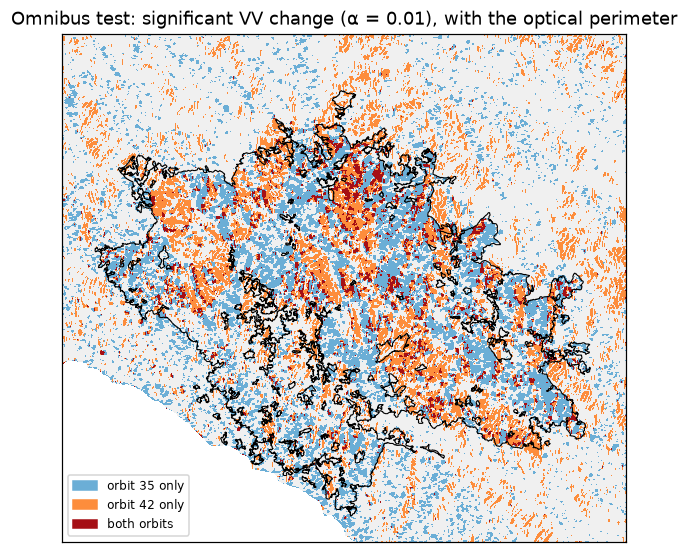

In [21]:
# omnibus likelihood-ratio test (Conradsen et al. 2016) on VV intensity, 20 Jul - 30 Sep (before the autumn rain),
# after 9 x 9 averaging; the ENL of the averaged data is estimated from the temporal variance over stable land
OMNI = {}
for o in ORBITS:
    x = S1[o].vv.sel(time=slice("2026-07-15", "2026-09-30"))
    xs = xr.apply_ufunc(lambda a: ndi.uniform_filter(a, (1, 9, 9)), x)
    enl = float(1 / np.var((xs / xs.mean("time")).values[:, stable]))
    OMNI[o] = change.omnibus_test(xs, enl=enl, alpha=0.01)["change"].values & land
    print(f"orbit {o}: {x.sizes['time']} dates, ENL {enl:.1f} | change flagged in {OMNI[o][burned].mean() * 100:.0f} % of the "
          f"perimeter ({OMNI[o][burned & (sev == 5)].mean() * 100:.0f} % of high severity) and {OMNI[o][stable].mean() * 100:.0f} % of stable land")
omni_any = OMNI[35] | OMNI[42]
print(f"either orbit: {omni_any[burned].mean() * 100:.0f} % of the perimeter, {omni_any[stable].mean() * 100:.0f} % of stable land")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(np.where(land, OMNI[35].astype(int) + 2 * OMNI[42].astype(int), np.nan),
          cmap=ListedColormap(["#f0f0f0", "#6baed6", "#fd8d3c", "#a50f15"]), vmin=-0.5, vmax=3.5, extent=EXT, interpolation="nearest")
ax.contour(burned[::-1], levels=[0.5], colors="k", linewidths=0.7, extent=EXT)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(["#6baed6", "#fd8d3c", "#a50f15"], ["orbit 35 only", "orbit 42 only", "both orbits"])],
          fontsize=8, loc="lower left")
ax.set_title("Omnibus test: significant VV change (α = 0.01), with the optical perimeter"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.show()

The omnibus test detects change in about 60 % of the perimeter with either orbit, but also in 17 % of the stable land. It answers the question "did anything change?", which in a summer landscape also includes drying vegetation, moving shadows and residual speckle, not "did it burn?". It is a useful screening tool, but not a burn map.

### Threshold and Random Forest

- **Threshold:** one Otsu threshold (`change.threshold`) on the combined-orbit cross-ratio change at 150 m.
- **Random Forest:** all 36 change features (VV, VH and cross ratio; each orbit and both; four scales) plus slope and both local incidence angles. Labels come from the optical map: burned = inside the perimeter; unburned = land more than 100 m outside it (edge pixels are left out). 20 000 pixels per class are split by **1 km spatial blocks** (30 % of blocks held out).


In [22]:
# (a) one threshold: Otsu on the combined-orbit cross-ratio change at 150 m
cr = SAR["dCR_both@150 m"]
thr = change.threshold(cr[land & np.isfinite(cr)], method="otsu")
sar_thr = land & (cr < thr)

# (b) Random Forest on all Sentinel-1 change features plus terrain, trained on the optical burn map
feat_names = list(SAR) + ["slope", "lia_35", "lia_42"]
FEAT = {**SAR, "slope": slope, "lia_35": LIA[35], "lia_42": LIA[42]}
label = np.full(land.shape, -1, "int8")
label[burned] = 1
label[land & ~burned & (ndi.distance_transform_edt(~burned) * RES > 100)] = 0     # 100 m buffer: no edge pixels in training
MAXN = 20_000
idx = np.concatenate([rng.choice(np.flatnonzero(label.ravel() == c), MAXN, replace=False) for c in (0, 1)])
rr, cc = np.unravel_index(idx, label.shape)
X_all = pd.DataFrame({n: np.nan_to_num(FEAT[n][rr, cc]) for n in feat_names})
y_all = label[rr, cc]
coords = np.column_stack([BOUNDS[0] + (cc + 0.5) * RES, BOUNDS[3] - (rr + 0.5) * RES])
split = ic.spatial_block_split(coords, block_size=1000, test_size=0.3, seed=SEED, stratify=y_all)
blocks = ic.spatial_blocks(coords, 1000)
ic.check_split_isolation(train=blocks[split.train], test=blocks[split.test])
t0 = time.time()
rf, cv = ic.train_pixel_classifier(X_all.iloc[split.train], y_all[split.train], model="rf", coords=coords[split.train],
                                   block_size=1000, n_splits=4, n_estimators=300, n_jobs=-1, seed=SEED)
print(f"Random Forest trained in {time.time() - t0:.0f} s on {len(split.train):,} pixels; spatial 4-fold CV accuracy "
      f"{cv['accuracy'].mean():.3f} ± {cv['accuracy'].std():.3f}")
rep = ic.classification_report(y_all[split.test], rf.predict(X_all.iloc[split.test]), labels=[0, 1],
                               class_names={0: "unburned", 1: "burned"}, n_boot=200)
print(f"held-out 1 km blocks: OA {rep['overall_accuracy']:.3f}, kappa {rep['kappa']:.3f}")
rep["per_class"].round(3)

Random Forest trained in 11 s on 28,319 pixels; spatial 4-fold CV accuracy 0.877 ± 0.015


held-out 1 km blocks: OA 0.905, kappa 0.807


,precision,recall,f1,support,f1_ci_low,f1_ci_high
unburned,0.908,0.919,0.914,6416,0.908,0.919
burned,0.900,0.887,0.893,5265,0.887,0.899


Random Forest recall by optical severity class: {'Low': np.float64(0.7), 'Moderate-low': np.float64(0.8), 'Moderate-high': np.float64(0.9), 'High': np.float64(0.95)}


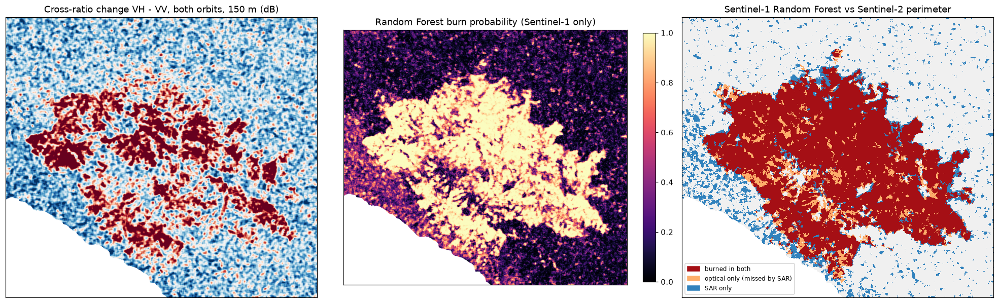

,burned km²,precision,recall,F1,IoU
S2 perimeter (reference),91.441,1.000,1.000,1.000,1.000
"S1 omnibus, either orbit",84.305,0.641,0.591,0.615,0.444
"S1 cross-ratio threshold (Otsu, -0.59 dB)",51.098,0.926,0.517,0.664,0.497
S1 Random Forest,99.480,0.801,0.871,0.834,0.716


In [23]:
fds = xr.Dataset({n: xr.DataArray(np.nan_to_num(FEAT[n]).astype("float32"), dims=("y", "x")) for n in feat_names})
prob = rf.model.predict_proba(np.stack([fds[n].values.ravel() for n in feat_names], 1))[:, 1].reshape(land.shape)
sar_rf = land & (prob >= 0.5)

def agreement(a, ref):
    tp = (a & ref).sum(); fp = (a & ~ref).sum(); fn = (~a & ref).sum()
    return {"burned km²": a.sum() * RES**2 / 1e6, "precision": tp / (tp + fp), "recall": tp / (tp + fn),
            "F1": 2 * tp / (2 * tp + fp + fn), "IoU": tp / (tp + fp + fn)}
comp = pd.DataFrame({"S2 perimeter (reference)": agreement(burned, burned),
                     "S1 omnibus, either orbit": agreement(omni_any, burned),
                     f"S1 cross-ratio threshold (Otsu, {thr:.2f} dB)": agreement(sar_thr, burned),
                     "S1 Random Forest": agreement(sar_rf, burned)}).T.round(3)
recall_sev = {SEV[k][0]: sar_rf[burned & (sev == k)].mean() for k in (2, 3, 4, 5)}
print("Random Forest recall by optical severity class:", {k: round(v, 2) for k, v in recall_sev.items()})

fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
ax[0].imshow(np.where(land, cr, np.nan), cmap="RdBu", vmin=-1.2, vmax=0.6, extent=EXT); ax[0].set_title("Cross-ratio change VH - VV, both orbits, 150 m (dB)")
im = ax[1].imshow(np.where(land, prob, np.nan), cmap="magma", vmin=0, vmax=1, extent=EXT); ax[1].set_title("Random Forest burn probability (Sentinel-1 only)")
plt.colorbar(im, ax=ax[1], fraction=0.04)
ax[2].imshow(np.where(land, sar_rf.astype(int) + 2 * burned.astype(int), np.nan),
             cmap=ListedColormap(["#f0f0f0", "#3182bd", "#fdae6b", "#a50f15"]), vmin=-0.5, vmax=3.5, extent=EXT, interpolation="nearest")
ax[2].legend(handles=[Patch(color=c, label=l) for c, l in zip(["#a50f15", "#fdae6b", "#3182bd"],
             ["burned in both", "optical only (missed by SAR)", "SAR only"])], fontsize=8, loc="lower left")
ax[2].set_title("Sentinel-1 Random Forest vs Sentinel-2 perimeter")
for a in ax:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
comp

**Reading the SAR maps.**

- The **threshold** map is precise (93 % of what it calls burned is inside the optical perimeter) but finds only half of the burned area: a single feature cannot follow the variable signal.
- The **Random Forest** reproduces the optical perimeter with F1 ≈ 0.83 and IoU ≈ 0.72 over the whole AOI, and with 0.90 accuracy on the held-out 1 km blocks. It finds 95 % of the high-severity area but only about 70 % of the low-severity area, where the canopy was only partly removed.
- Its errors are false alarms on the coastal grassland and scattered patches in the unburned forest, and missed patches along the burn edges and in lightly burned canyons. The 150 m features make the SAR perimeter smoother than the optical one.

The training labels come from Sentinel-2, so these scores say how well SAR can **reproduce** the optical map, which is the right question when clouds or smoke block the optics.


## Fire growth from Sentinel-1


To date the burn from SAR, we fit a **change point** to each pixel of the (cleaned) SAR burn map: the date, from 7 August on, that best splits its combined-orbit cross-ratio series (20 July – 30 September, 150 m) into a higher "before" and a lower "after" level, with a drop of at least 0.3 dB. Single dates are too noisy for a threshold; a change point uses the whole series.


SAR burn map (cleaned): 97.4 km²; dated by the change-point fit: 73 %
pixels dated by both sensors: 61.2 km²; SAR date minus optical date: median +2 days, within ±6 days: 52 %, within ±12 days: 66 %


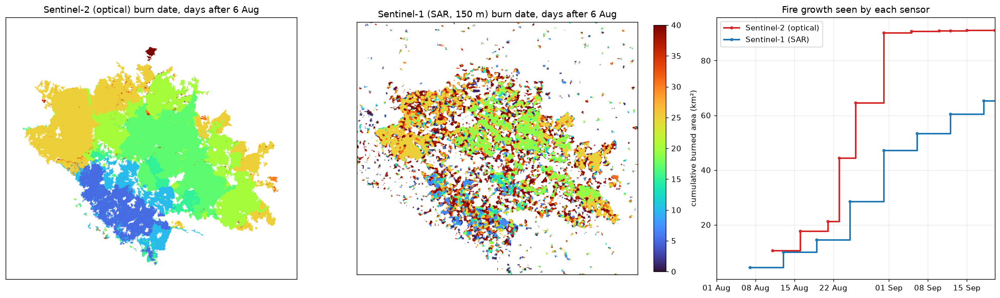

In [24]:
# SAR burn date: both orbits image the AOI on the same days (ascending ~19:06 and descending ~07:07 local time).
# Single dates are too noisy for a threshold, so we fit a step (change point) to each pixel's series instead:
# the date that best splits the cross-ratio change (both orbits, 150 m, 20 Jul - 30 Sep) into a higher "before"
# and a lower "after" level, by least squares.
sar_burned = ic.clean_mask(sar_rf, min_size=100, hole_size=100, opening=0).astype(bool)
s1_times = pd.DatetimeIndex(DB[(35, "vh")].time.values)
use = np.asarray(s1_times <= pd.Timestamp("2026-09-30"))
cr_pre = {o: period_mean(DB[(o, "vh")], S1_PRE) - period_mean(DB[(o, "vv")], S1_PRE) for o in ORBITS}
x = np.stack([smooth(np.mean([(DB[(o, "vh")].values[i] - DB[(o, "vv")].values[i]) - cr_pre[o] for o in ORBITS], 0), 15)
              for i in np.flatnonzero(use)])
tt = s1_times[use]
best_sse, best_k = np.full(land.shape, np.inf), np.full(land.shape, -1)
k_first = int(np.argmax(tt >= pd.Timestamp("2026-08-07")))   # the first acquisition after the last unburned optical date
for k in range(max(2, k_first), len(tt) - 1):            # at least two dates on each side
    before, after = x[:k], x[k:]
    sse = ((before - before.mean(0)) ** 2).sum(0) + ((after - after.mean(0)) ** 2).sum(0)
    step_down = after.mean(0) < before.mean(0) - 0.3     # a drop of at least 0.3 dB
    better = step_down & (sse < best_sse)
    best_sse[better], best_k[better] = sse[better], k
ok = sar_burned & (best_k >= 0)
s1_burn_date = np.where(ok, tt.values[np.clip(best_k, 0, None)], np.datetime64("NaT"))
s1_dated = ~np.isnat(s1_burn_date)
print(f"SAR burn map (cleaned): {sar_burned.sum() * RES**2 / 1e6:.1f} km²; dated by the change-point fit: {s1_dated[sar_burned].mean() * 100:.0f} %")

both = s1_dated & dated
lag = (s1_burn_date[both] - s2_burn_date[both]).astype("timedelta64[D]").astype(int)
print(f"pixels dated by both sensors: {both.sum() * RES**2 / 1e6:.1f} km²; SAR date minus optical date: median {np.median(lag):+.0f} days, "
      f"within ±6 days: {(np.abs(lag) <= 6).mean() * 100:.0f} %, within ±12 days: {(np.abs(lag) <= 12).mean() * 100:.0f} %")

ref = np.datetime64("2026-08-06")
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for a, (bd, msk, ttl) in zip(ax[:2], [(s2_burn_date, dated, "Sentinel-2 (optical)"), (s1_burn_date, s1_dated, "Sentinel-1 (SAR, 150 m)")]):
    im = a.imshow(np.where(msk, (bd - ref).astype("timedelta64[D]").astype(float), np.nan), cmap="turbo", vmin=0, vmax=40, extent=EXT)
    a.set_title(f"{ttl} burn date, days after 6 Aug"); a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.colorbar(im, ax=ax[1], fraction=0.04)
for bd, msk, c, l in [(s2_burn_date, dated, "tab:red", "Sentinel-2 (optical)"), (s1_burn_date, s1_dated, "tab:blue", "Sentinel-1 (SAR)")]:
    cum = pd.Series(bd[msk]).value_counts().sort_index().cumsum() * RES**2 / 1e6
    ax[2].step(cum.index, cum.values, where="post", color=c, lw=2, label=l, marker="o", ms=3)
ax[2].set_xlim(pd.Timestamp("2026-08-01"), pd.Timestamp("2026-09-20")); ax[2].legend()
ax[2].set_ylabel("cumulative burned area (km²)"); ax[2].set_title("Fire growth seen by each sensor")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

**Reading the comparison.** Where both sensors date the burn, the SAR date is a median of 2 days after the optical date; about half of the pixels agree within one Sentinel-1 revisit (6 days) and two thirds within two. The SAR map shows the same pattern as the optical one: the south burned first, the north and east last. The SAR growth curve lags and flattens because a quarter of the SAR-burned pixels get no clear change point and the 150 m averaging mixes pixels that burned on different dates. In this fire Sentinel-2 saw the ground through the smoke on most dates, so it gives the sharper reconstruction; with a cloudier fire, the SAR record would be the only one.


## Terrain effects on severity and on SAR detection


In [25]:
ASPECTS = {"N": (315, 45), "E": (45, 135), "S": (135, 225), "W": (225, 315)}
def aspect_class(a):
    out = np.full(a.shape, "", object)
    for k, (lo, hi) in ASPECTS.items():
        out[(a >= lo) & (a < hi) if lo < hi else (a >= lo) | (a < hi)] = k
    return out
asp = aspect_class(aspect)
rows = []
for k in ASPECTS:
    m = burned & (asp == k) & (slope > 5)
    rows.append({"aspect": k, "burned km²": m.sum() * RES**2 / 1e6, "median dNBR": np.median(dn[m]),
                 "high severity (%)": (sev[m] == 5).mean() * 100,
                 "S1 RF recall (%)": sar_rf[m].mean() * 100,
                 "orbit 35 usable (%)": TERRAIN_OK[35][m].mean() * 100, "orbit 42 usable (%)": TERRAIN_OK[42][m].mean() * 100})
by_aspect = pd.DataFrame(rows).set_index("aspect").round(2)
bins = [0, 15, 25, 35, 90]
sl_cls = pd.cut(pd.Series(slope[burned]), bins, labels=[f"{a}-{b}°" for a, b in zip(bins[:-1], bins[1:])])
by_slope = pd.DataFrame({"burned km²": pd.Series(np.ones(burned.sum())).groupby(sl_cls).sum() * RES**2 / 1e6,
                         "median dNBR": pd.Series(dn[burned]).groupby(sl_cls).median(),
                         "S1 RF recall (%)": pd.Series(sar_rf[burned].astype(float)).groupby(sl_cls).mean() * 100}).round(2)
print("Burn severity and SAR detection by slope aspect (slopes > 5°):"); print(by_aspect)
print("\nBy slope class:"); print(by_slope)

Burn severity and SAR detection by slope aspect (slopes > 5°):
        burned km²  median dNBR  high severity (%)  S1 RF recall (%)  \
aspect                                                                 
N            17.33         0.47              30.56             74.24   
E            19.51         0.56              37.92             86.58   
S            28.75         0.56              34.03             93.67   
W            25.41         0.55              36.10             89.09   

        orbit 35 usable (%)  orbit 42 usable (%)  
aspect                                            
N                     99.33                99.25  
E                     91.94                64.22  
S                    100.00                99.99  
W                     57.95                90.00  

By slope class:
        burned km²  median dNBR  S1 RF recall (%)
0-15°         5.83         0.47             77.64
15-25°       19.27         0.54             82.62
25-35°       41.12         0.57

- **North-facing slopes** burned less severely (median dNBR 0.47, against 0.55–0.56 on the other aspects): they are usually cooler and moister. They are also where the SAR misses most (recall 74 %, against 86–94 % on the other aspects).
- **West-facing slopes** are foreshortened for the ascending orbit (only 58 % usable) and **east-facing slopes** for the descending orbit (64 % usable): each orbit fills the other's gap.
- SAR recall **increases with slope** (from 78 % below 15° to 91 % above 35°). A likely reason is fuel: gentle slopes near the coast carry grass and low scrub, whose removal changes the backscatter little, while the steep slopes carry denser chaparral.


## Writing the outputs


In [26]:
import rioxarray  # noqa: F401  (registers the .rio accessor)
tmpl = xr.DataArray(np.zeros(land.shape, "float32"), dims=("y", "x"),
                    coords={"y": BOUNDS[3] - (np.arange(land.shape[0]) + 0.5) * RES, "x": BOUNDS[0] + (np.arange(land.shape[1]) + 0.5) * RES})
written = []
def write(name, arr, dtype="float32", nodata=np.nan, desc=""):
    da = tmpl.copy(data=np.asarray(arr).astype(dtype)).rio.write_crs(CRS).rio.write_nodata(nodata)
    da.attrs["description"] = desc
    p = OUT / f"{name}.tif"; da.rio.to_raster(p, compress="deflate"); written.append(p)

ref = np.datetime64("2026-08-06")
write("dnbr", np.where(land, dn, np.nan), desc="dNBR, pre 17 Jul-6 Aug, post 25 Sep-15 Oct 2026")
write("rdnbr", np.where(land, rdnbr.values, np.nan), desc="RdNBR x1000")
write("burn_severity_classes", np.where(land, sev, -1), "int8", -1, "Key & Benson 2006 dNBR classes 0-5")
write("s2_burn_date_days_since_2026-08-06", np.where(dated, (s2_burn_date - ref).astype("timedelta64[D]").astype(float), np.nan),
      desc="optical burn date")
write("s1_burn_probability", np.where(land, prob, np.nan), desc="Sentinel-1 Random Forest burn probability")
write("s1_burn_date_days_since_2026-08-06", np.where(s1_dated, (s1_burn_date - ref).astype("timedelta64[D]").astype(float), np.nan),
      desc="SAR change-point burn date")

def to_polys(mask, name):
    da = tmpl.copy(data=mask.astype("int32")).rio.write_crs(CRS)
    g = [shape(geom) for geom, v in rfeat.shapes(mask.astype("uint8"), mask=mask, transform=gb.affine) if v == 1]
    gdf = gpd.GeoDataFrame({"source": [name] * len(g)}, geometry=g, crs=CRS)
    gdf["area_ha"] = gdf.area / 1e4
    return gdf[gdf.area_ha >= 1].reset_index(drop=True)

perim = pd.concat([to_polys(burned, "Sentinel-2 dNBR perimeter"), to_polys(sar_burned, "Sentinel-1 Random Forest")], ignore_index=True)
perim.to_file(OUT / "fire_perimeters.gpkg", layer="perimeters", driver="GPKG"); written.append(OUT / "fire_perimeters.gpkg")
tab.to_csv(OUT / "burn_severity_area.csv"); growth.to_csv(OUT / "fire_growth_sentinel2.csv")
comp.to_csv(OUT / "sar_vs_optical_agreement.csv"); s1_inv.to_csv(OUT / "sentinel1_inventory.csv"); s2_inv.to_csv(OUT / "sentinel2_inventory.csv")
written += [OUT / f for f in ["burn_severity_area.csv", "fire_growth_sentinel2.csv", "sar_vs_optical_agreement.csv",
                               "sentinel1_inventory.csv", "sentinel2_inventory.csv"]]
print(perim.groupby("source").agg(polygons=("area_ha", "size"), km2=("area_ha", lambda a: a.sum() / 100)).round(1))
for p in written:
    print(f"{p.name:48s} {p.stat().st_size / 1e6:7.2f} MB")

                           polygons   km2
source                                   
Sentinel-1 Random Forest        252  97.4
Sentinel-2 dNBR perimeter        26  91.4
dnbr.tif                                            8.93 MB
rdnbr.tif                                           9.11 MB
burn_severity_classes.tif                           0.31 MB
s2_burn_date_days_since_2026-08-06.tif              0.19 MB
s1_burn_probability.tif                             4.23 MB
s1_burn_date_days_since_2026-08-06.tif              0.34 MB
fire_perimeters.gpkg                                1.59 MB
burn_severity_area.csv                              0.00 MB
fire_growth_sentinel2.csv                           0.00 MB
sar_vs_optical_agreement.csv                        0.00 MB
sentinel1_inventory.csv                             0.00 MB
sentinel2_inventory.csv                             0.00 MB


The rasters are on the 10 m UTM 10N grid. The perimeters file holds both the Sentinel-2 perimeter and the Sentinel-1 Random Forest burn map as polygons of at least 1 ha. The SAR map is split into more polygons because of its isolated false alarms.


## Interpretation, caveats and recommended recipe


**What the measured numbers say** (AOI 267 km², 89 % land, 15 July – 31 October 2026; 25 Sentinel-2 days, 18 of them cloud-free; 36 Sentinel-1 acquisitions on two orbits):

* **The fire.** The last unburned clear image is from 6 August. The fire was burning near the coast on 11 August, grew in large runs between 21 and 31 August, and was essentially at its final extent of about **91 km²** (37 % of the land in the AOI) by 31 August.
* **Severity.** About two thirds of the burned area is moderate-high or high severity by dNBR, and 70 % is "high" by RdNBR. North-facing slopes burned less severely.
* **Smoke** affected five of the clear dates in August. It did not stop the optical mapping, because NBR uses NIR and SWIR, but it would have hidden the fire in true-colour images.
* **Seasonal drying** of coastal grassland mimics low-severity burn in a dNBR map. Requiring an abrupt NBR drop between consecutive observations separates the two.
* **SAR sees the burn, but weakly per pixel.** After the fire VV rises by about 0.5 dB and the cross ratio falls; VH alone carries almost no signal in this shrubland. Combining the two orbits and averaging to 150 m raises the separability from AUC ≈ 0.68 to 0.90.
* **SAR alone can reproduce the optical perimeter**: a Random Forest on Sentinel-1 change features agrees with the Sentinel-2 perimeter with F1 ≈ 0.83 (IoU ≈ 0.72), finds 95 % of the high-severity area, and dates the burn within one 6-day revisit for about half of the pixels. A single threshold or the omnibus test alone do much worse.

**Caveats**

* **No ground reference.** The severity classes are the standard dNBR classes, not calibrated against field plots (Composite Burn Index) for this fire; the SAR scores measure agreement with Sentinel-2, not with the ground.
* **The SAR model learns from the optical map.** It needs a few clear optical images (here available) to be trained; for a fully cloud-covered fire it would have to be trained on another fire.
* **Rain at the end of the series.** The first storms in late October changed soil moisture; the SAR post-fire period includes October dates, and the normalisation to unburned land removes only the regional part of the effect.
* **Resolution.** The SAR maps work at about 150 m effective resolution; unburned islands and narrow burned fingers below that size are lost.
* **Terrain.** Local incidence angles are computed with a single nominal incidence angle (38°); the true angle varies by a few degrees across the AOI.
* **AOI only.** The fire perimeter is clipped to the AOI; if the fire extended beyond the rectangle, its total size is larger.

**Recommended recipe**

1. Build the Sentinel-2 series with per-pixel SCL masking (keep the dark-area class), select cloud-free dates on the land fraction, and flag smoke with the blue band.
2. Compute pre- and post-fire NBR as medians of several clear dates; map dNBR, RdNBR and severity classes; separate fire from seasonal drying with an abrupt-drop test.
3. Date each pixel's burn from the first observation with half of its final NBR drop, and plot the growth.
4. For Sentinel-1, use both orbits, normalise each date to stable unburned land (removes platform and weather offsets), filter speckle multi-temporally, and mask foreshortened and shadowed slopes per orbit.
5. Use VV and cross-ratio change at several scales; train a classifier on optical labels with a spatial block split, and date the burn with a change-point fit.
6. To go further: collect Composite Burn Index plots, add an L-band sensor (NISAR) for forest canopies, and add the coherence of the Sentinel-1 SLC pairs, which drops sharply when vegetation burns.

**References**

- Key, C. H., & Benson, N. C. (2006). Landscape assessment: ground measure of severity, the Composite Burn Index; and remote sensing of severity, the Normalized Burn Ratio. USDA Forest Service, RMRS-GTR-164-CD.
- Miller, J. D., & Thode, A. E. (2007). Quantifying burn severity in a heterogeneous landscape with a relative version of the delta Normalized Burn Ratio (dNBR). *Remote Sensing of Environment*, 109(1), 66–80.
- Conradsen, K., Nielsen, A. A., & Skriver, H. (2016). Determining the points of change in time series of polarimetric SAR data. *IEEE TGRS*, 54(5), 3007–3024.
- Quegan, S., & Yu, J. J. (2001). Filtering of multichannel SAR images. *IEEE TGRS*, 39(11), 2373–2379.
- Tanase, M. A., Santoro, M., de la Riva, J., Pérez-Cabello, F., & Le Toan, T. (2010). Sensitivity of X-, C-, and L-band SAR backscatter to burn severity in Mediterranean pine forests. *IEEE TGRS*, 48(10), 3663–3675.
- Filipponi, F. (2018). BAIS2: Burned Area Index for Sentinel-2. *Proceedings*, 2(7), 364.
